In [68]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal
import numpy as np

In [69]:
class QuadraticState(TypedDict):
    a : int
    b : int
    c : int
    equation : str
    discriminant: float
    result: str

In [70]:
def show_equation(state: QuadraticState):
    
    equation = f"{state['a']}x^2 + {state['b']}x + {state['c']}"
  
    return {'equation' : equation}

def calculate_discriminant(state: QuadraticState):
    
    discriminant = state['b']**2 - (4*state['a']*state['c'])
  
    return {'discriminant' : discriminant}    

def real_roots(state: QuadraticState):

    root1 = (-state['b'] + np.sqrt(state['discriminant']))/(2*state['a'])
    root2 = (-state['b'] - np.sqrt(state['discriminant']))/(2*state['a'])
    
    result = f"The Real Roots are {root1} & {root2}"
    return {'result': result}

def repeated_roots(state: QuadraticState):

    root = -(state['b'])/(2*state['a'])

    result = f"Only Repeated Root: {root}"

    return {'result': result}

def no_real_roots(state: QuadraticState):
    
    result = "No Real Roots!"

    return {'result': result}      

def check_discriminant(state: QuadraticState) -> Literal['Real_Roots','Repeated_Roots','No_Real_Roots']:

    if state['discriminant'] > 0:
        return 'Real_Roots'
    elif state['discriminant'] == 0:
        return 'Repeated_Roots'
    else:
        return 'No_Real_Roots'        
    

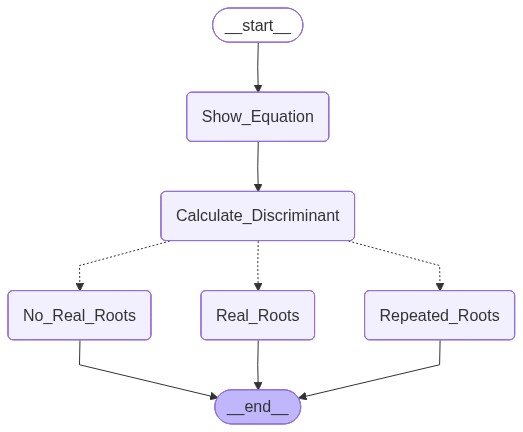

In [71]:
graph = StateGraph(QuadraticState)

graph.add_node('Show_Equation', show_equation)

graph.add_node('Calculate_Discriminant', calculate_discriminant)
graph.add_node('Real_Roots', real_roots)
graph.add_node('Repeated_Roots', repeated_roots)
graph.add_node('No_Real_Roots', no_real_roots)

graph.add_edge(START, 'Show_Equation')

graph.add_edge('Show_Equation', 'Calculate_Discriminant')

graph.add_conditional_edges('Calculate_Discriminant',check_discriminant)

graph.add_edge(['Real_Roots','Repeated_Roots','No_Real_Roots'], END)

quad_workflow = graph.compile()

quad_workflow

In [73]:
input_state = {'a':2 , 'b':4 , 'c':-2}

final_state = quad_workflow.invoke(input_state)

print(final_state)

{'a': 2, 'b': 4, 'c': -2, 'equation': '2x^2 + 4x + -2', 'discriminant': 32, 'result': 'The Real Roots are 0.41421356237309515 & -2.414213562373095'}
